# Pricing and Promotions
### How sensitive is each product to price, which promotions pay, and what should change?

**Dataset:** dunnhumby *Breakfast at the Frat*: 156 weeks (January 2009 to January 2012) of unit sales, shelf prices, base prices and promotional support for 58 products in 4 categories (bag snacks, cold cereal, frozen pizza, oral hygiene) across 77 stores in Texas, Ohio, Kentucky and Indiana.
**Stack:** dbt on DuckDB, pandas, pyfixest (high-dimensional fixed-effects regression), a revenue and profit simulator.

Notebook 02 showed that the wholesaler's own data can say that demand is elastic, but not by how much for each product, and nothing about promotions, because that business runs none. This notebook uses a retail dataset designed for exactly these questions.

| # | Step | Question it answers |
|---|------|---------------------|
| 1 | Business problem | Which pricing and promotion decisions are we supporting? |
| 2 | Data and dbt models | How is the store-week panel built? |
| 3 | Data audit | What in the data needs a rule? |
| 4 | Exploratory analysis | Price ladders, promotion mechanics, raw lifts |
| 5 | Why a naive regression misleads | Confounding, and how fixed effects remove it |
| 6 | The elasticity model | Product-level price sensitivity with honest uncertainty |
| 7 | Promotion effects | Circular, display, shelf tag and discount depth |
| 8 | Side effects of promotions | Pantry loading and cannibalization |
| 9 | Out-of-time validation | Does the model predict weeks it has never seen? |
| 10 | Promotion economics | Which promotions make money? |
| 11 | Base price recommendations | Where is the price too low or too high? |
| 12 | The simulator | Scenarios a category manager can run |
| 13 | Conclusions | What we learned |
| 14 | Limitations and next steps | What we would do next |

Production code lives in `src/retail_intelligence/pricing.py`; the app and the AI analyst use the results exported by `python -m retail_intelligence.pricing`.

In [1]:
import json
import warnings
warnings.filterwarnings("ignore")   # keep the notebook output focused on results

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from retail_intelligence import pricing as pr
from retail_intelligence.config import DATA_RAW, DEFAULT_GROSS_MARGIN
from retail_intelligence.plotting import BLUE, CATEGORICAL, GRAY, INK, LIGHT_BLUE, MUTED, RED, apply_style, save

apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
CAT_COLORS = dict(zip(["Bag snacks", "Cold cereal", "Frozen pizza", "Oral hygiene products"], CATEGORICAL))

## 1. Business problem

A category manager at a grocery chain owns four categories. Every quarter they set **base prices** and plan **promotions**: temporary price reductions (TPR), a slot in the weekly **circular** (feature), and **in-store displays**. Suppliers fund part of the cost, but every promotion gives away margin on units that would have sold anyway.

The questions:

1. **Price sensitivity.** If the base price of a product goes up 5%, how many units are lost? (Own-price elasticity, per product.)
2. **Promotion effectiveness.** How much extra volume does a circular feature, a display or a deeper discount bring?
3. **Side effects.** Do promotions only pull demand forward (pantry loading) or steal it from other products in the same category (cannibalization)?
4. **Decisions.** Which promotions make money at a realistic margin, and which base prices should be tested higher or lower?

**How the work is judged:** coefficients must be plausible and come with confidence intervals; the model must predict weeks it has never seen better than simple baselines; recommendations must state their assumptions (above all the margin, which is not in the data).

## 2. Data and dbt models

The source is an Excel workbook with three sheets. `python -m retail_intelligence.ingest_pricing` downloads it from dunnhumby and writes one Parquet file per sheet. dunnhumby's files are free for learning and case studies but all rights reserved, so the raw data and the row-level panel are never committed; only aggregated model outputs are.

```
source dunnhumby.transactions ──> stg_frat_sales     cleaning rules 1 to 4, discount depth, promotion flags
source dunnhumby.products     ──> stg_frat_products  category, manufacturer, size
source dunnhumby.stores       ──> stg_frat_stores    price tier, state; rule 5 removes duplicated stores
                                      └──> pricing_store_weeks (one row per store, product and week)
```

In [2]:
d = pr.load_panel()
display(Markdown(
    f"**Panel:** {len(d):,} store-product-weeks, {d.store_id.nunique()} stores, {d.upc.nunique()} products, "
    f"{d.week_end.nunique()} weeks ({d.week_end.min():%d %b %Y} to {d.week_end.max():%d %b %Y})."))
d[["week_end", "store_id", "price_tier", "description", "category", "units", "price", "base_price",
   "discount_depth", "is_feature", "is_display", "is_tpr_only"]].head()

**Panel:** 524,674 store-product-weeks, 77 stores, 55 products, 156 weeks (14 Jan 2009 to 04 Jan 2012).

,week_end,store_id,price_tier,description,category,units,price,base_price,discount_depth,is_feature,is_display,is_tpr_only
0,2012-01-04,6379,Mainstream,POST FRUITY PEBBLES,Cold cereal,19,2.250,2.620,0.141,0,0,1
1,2012-01-04,6379,Mainstream,POST FM SZ HNYBNCH OT ALM,Cold cereal,23,2.920,2.920,0.000,0,0,0
2,2012-01-04,6379,Mainstream,POST HNY BN OTS HNY RSTD,Cold cereal,14,2.920,2.920,0.000,0,0,0
3,2012-01-04,6379,Mainstream,LSTRNE FRS BRST ANTSPC MW,Oral hygiene products,3,4.970,4.970,0.000,0,0,0
4,2012-01-04,6379,Mainstream,LSTRNE CL MINT ANTSPTC MW,Oral hygiene products,13,4.970,4.970,0.000,0,0,0


## 3. Data audit

The dunnhumby user guide warns that a small share of rows are outliers. Every finding below became a rule in dbt, with a data test where it can be expressed as one.

In [3]:
raw = pd.read_parquet(DATA_RAW / "dunnhumby" / "transactions.parquet")
stores = pd.read_parquet(DATA_RAW / "dunnhumby" / "stores.parquet")
products_raw = pd.read_parquet(DATA_RAW / "dunnhumby" / "products.parquet")
bad_price = raw.price.isna() | (raw.price <= 0) | raw.base_price.isna() | (raw.base_price <= 0)
checks = pd.DataFrame([
    ("Missing or zero shelf or base price", bad_price.sum(), "Drop: no price, no elasticity", "Rule 1"),
    ("Zero units", (raw.units == 0).sum(), "Drop: out of stock or delisted", "Rule 2"),
    ("More than 5 units per basket", (raw.units > 5 * raw.visits).sum(), "Drop: bulk buying, not shopper demand", "Rule 3"),
    ("Shelf price above base price", (raw.price > raw.base_price * 1.001).sum(), "Keep, discount set to 0", "Rule 4"),
    ("Stores listed twice with different price tiers", int(stores.store_id.duplicated().sum()), "One row per store (Mainstream)", "Rule 5"),
    ("Products in the lookup that never sell", len(set(products_raw.upc) - set(raw.upc)), "No action: absent from the panel", "-"),
    ("Duplicate store-product-weeks", int(raw.duplicated(["week_end_date", "store_num", "upc"]).sum()), "None found; enforced by a dbt test", "Test"),
], columns=["check", "rows", "decision", "rule"])
checks["share"] = checks["rows"] / len(raw)
display(checks.style.format({"rows": "{:,}", "share": "{:.2%}"}).hide(axis="index"))
display(Markdown(f"After cleaning, **{len(d):,} of {len(raw):,} rows ({len(d) / len(raw):.2%})** remain."))

check,rows,decision,rule,share
Missing or zero shelf or base price,209,"Drop: no price, no elasticity",Rule 1,0.04%
Zero units,5,Drop: out of stock or delisted,Rule 2,0.00%
More than 5 units per basket,67,"Drop: bulk buying, not shopper demand",Rule 3,0.01%
Shelf price above base price,"6,047","Keep, discount set to 0",Rule 4,1.15%
Stores listed twice with different price tiers,2,One row per store (Mainstream),Rule 5,0.00%
Products in the lookup that never sell,3,No action: absent from the panel,-,0.00%
Duplicate store-product-weeks,0,None found; enforced by a dbt test,Test,0.00%


After cleaning, **524,674 of 524,950 rows (99.95%)** remain.

The duplicated stores deserve attention: joining a lookup with duplicate keys silently doubles every sales row of those stores, inflating their volume in every model. A `unique` test on `stg_frat_stores.store_id` caught it during development, which is exactly what data tests are for.

## 4. Exploratory analysis

### 4.1 The categories over time

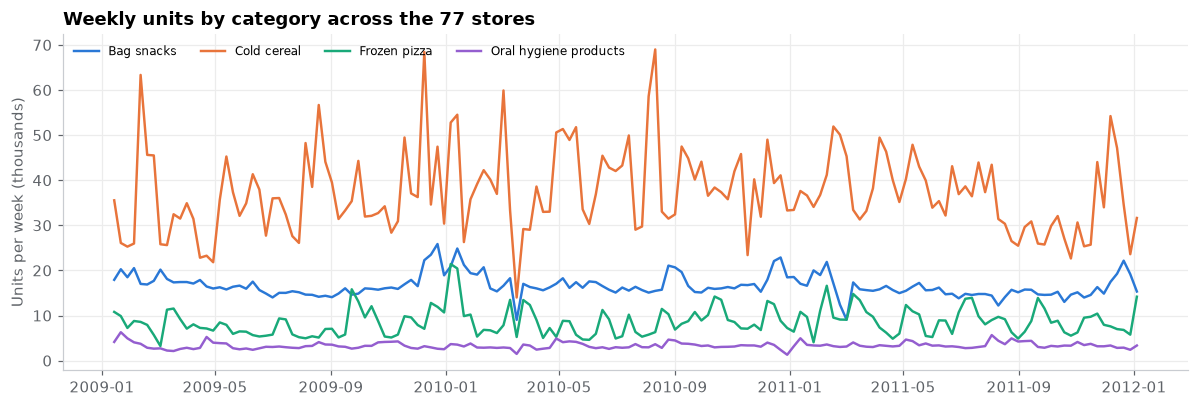

In [4]:
weekly = d.groupby(["week_end", "category"]).units.sum().unstack()
fig, ax = plt.subplots(figsize=(11, 3.8))
for c in weekly.columns:
    ax.plot(weekly.index, weekly[c] / 1e3, color=CAT_COLORS[c], lw=1.6, label=c)
ax.set(ylabel="Units per week (thousands)", title="Weekly units by category across the 77 stores")
ax.legend(loc="upper left", ncol=4, fontsize=8)
save(fig, "pricing_01_weekly_units")

Cereal sells the most units and is spiky: the spikes line up with chain-wide promotions. Frozen pizza is spiky too. This is the first hint that promotions, not seasons, drive most of the week-to-week movement in these categories.

### 4.2 Price ladders

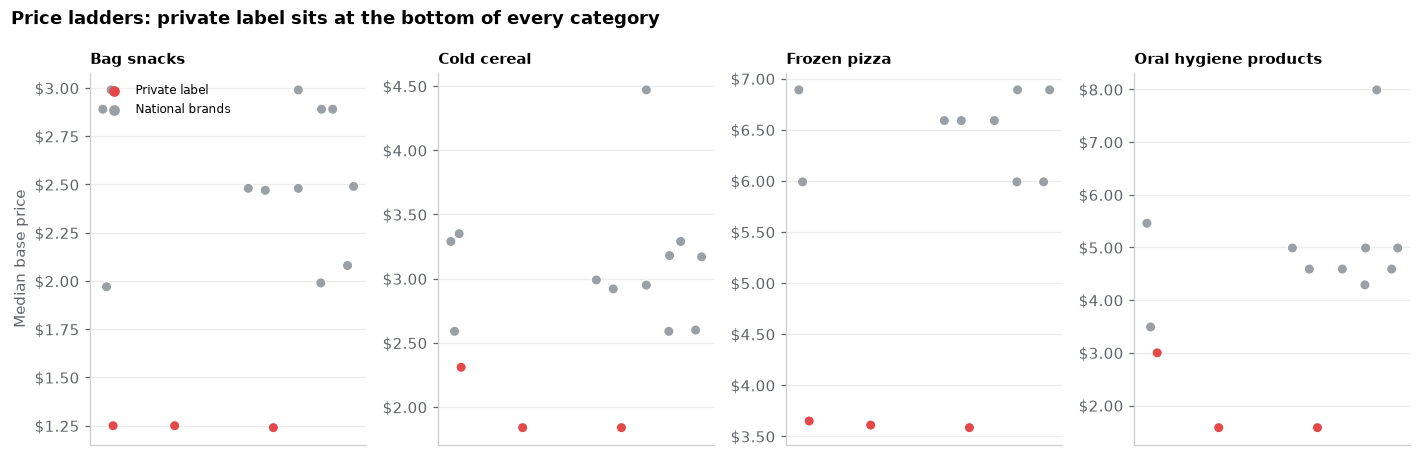

In [5]:
ladder = (d.groupby(["category", "upc", "description", "manufacturer"]).base_price.median()
            .reset_index().sort_values(["category", "base_price"]))
fig, axes = plt.subplots(1, 4, figsize=(13, 4.2), sharey=False)
for ax, (cat, g) in zip(axes, ladder.groupby("category")):
    pl = g.manufacturer.eq("PRIVATE LABEL")
    ax.scatter(np.zeros(len(g)) + np.random.default_rng(0).uniform(-0.15, 0.15, len(g)), g.base_price,
               c=np.where(pl, RED, GRAY), s=45, edgecolor="white", linewidth=0.8)
    ax.set_xticks([]); ax.set_title(cat, fontsize=10)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.2f}"))
axes[0].set_ylabel("Median base price")
axes[0].scatter([], [], color=RED, label="Private label"); axes[0].scatter([], [], color=GRAY, label="National brands")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Price ladders: private label sits at the bottom of every category", x=0.01, ha="left", fontweight="bold")
save(fig, "pricing_02_price_ladders")

### 4.3 How products are promoted

,promoted,feature,display,tpr_only,avg_discount_when_promoted
category,,,,,
Bag snacks,30.4%,2.5%,12.8%,16.3%,15.2%
Cold cereal,23.7%,9.6%,8.8%,11.0%,21.0%
Frozen pizza,30.6%,16.7%,14.7%,8.6%,21.4%
Oral hygiene products,31.2%,5.4%,8.7%,18.7%,24.0%


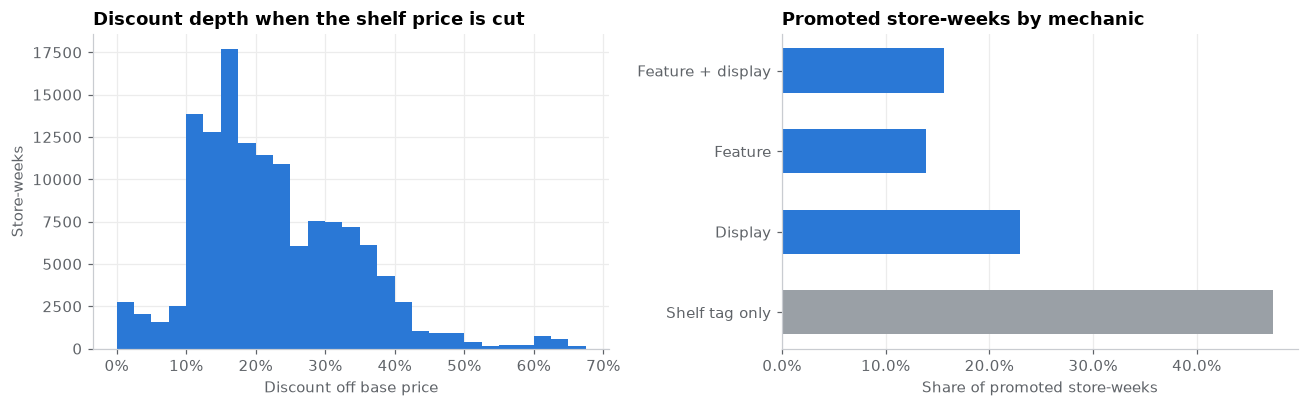

In [6]:
mech = d.groupby("category").agg(
    promoted=("is_promo", "mean"), feature=("is_feature", "mean"), display=("is_display", "mean"),
    tpr_only=("is_tpr_only", "mean"),
    avg_discount_when_promoted=("discount_depth", lambda s: s[d.loc[s.index, "is_promo"] == 1].mean()))
display(mech.style.format("{:.1%}"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
disc = d.loc[d.discount_depth > 0.005, "discount_depth"]
axes[0].hist(disc, bins=np.arange(0, 0.7, 0.025), color=BLUE)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set(title="Discount depth when the shelf price is cut", xlabel="Discount off base price", ylabel="Store-weeks")
combo = d[d.is_promo == 1].assign(
    mechanic=lambda x: np.select([(x.is_feature == 1) & (x.is_display == 1), x.is_feature == 1, x.is_display == 1],
                                 ["Feature + display", "Feature", "Display"], "Shelf tag only"))
share = combo.mechanic.value_counts(normalize=True).reindex(["Shelf tag only", "Display", "Feature", "Feature + display"])
axes[1].barh(share.index, share.values, color=[GRAY, BLUE, BLUE, BLUE], height=0.55)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].set(title="Promoted store-weeks by mechanic", xlabel="Share of promoted store-weeks")
axes[1].grid(axis="y", visible=False)
save(fig, "pricing_03_promotion_mechanics")

About a quarter of store-weeks carry some promotion. Most discounts are 10 to 35% off, and the mechanics are mixed: a shelf-tag-only price cut is the most common, while circular features usually come with a price cut and often with a display.

### 4.4 Raw promotional lift

In [7]:
raw_lift = (d.groupby(["category", "upc", "store_id", "is_promo"]).units.mean().unstack()
              .dropna().pipe(lambda t: t[1] / t[0]).groupby("category").median())
display(raw_lift.to_frame("median units on promotion / units off promotion").style.format("{:.2f}x"))

,median units on promotion / units off promotion
category,
Bag snacks,1.44x
Cold cereal,2.45x
Frozen pizza,2.51x
Oral hygiene products,1.45x


On promotion, a typical product sells 1.4 to 2.5 times its normal volume in the same store, most in cereal and pizza. But this raw ratio mixes everything: the discount, the circular, the display, and the fact that retailers schedule promotions in weeks when demand is high anyway. Separating these effects is the job of the model.

## 5. Why a naive regression misleads

The simplest estimate of elasticity regresses log units on log price across all rows. Each step below adds controls; watch the price coefficient move.

In [8]:
d["log_price"] = np.log(d.price)
specs = {
    "1. Naive: log units on log price": "log_units ~ log_price",
    "2. + store x product effects": "log_units ~ log_price | store_product",
    "3. + category x week effects": "log_units ~ log_price | store_product + category_week",
    "4. + circular, display and shelf tag": "log_units ~ log_price + is_feature + is_display + is_tpr_only | store_product + category_week",
}
steps = []
for name, f in specs.items():
    t = pr._feols(f, d).tidy().loc["log_price"]
    steps.append({"specification": name, "price elasticity": t["Estimate"], "std. error": t["Std. Error"]})
steps = pd.DataFrame(steps)
steps.style.format({"price elasticity": "{:.2f}", "std. error": "{:.3f}"}).hide(axis="index")

specification,price elasticity,std. error
1. Naive: log units on log price,-0.98,0.018
2. + store x product effects,-2.36,0.062
3. + category x week effects,-2.39,0.060
"4. + circular, display and shelf tag",-1.73,0.049


**Reading the table.**

1. **Naive (about -1).** Across all rows, expensive products are also big brands that sell well, and upscale stores charge more but also sell more. Those differences have nothing to do with how a shopper reacts to a price change, and they pull the estimate towards zero.
2. **Store x product effects.** Comparing each product in each store only with itself removes those permanent differences. Sensitivity more than doubles.
3. **Category x week effects.** Absorb seasonality, holidays, weather and anything that moves the whole category in a given week. Little changes here, a sign that price cuts are not just timed with high-demand weeks.
4. **Promotional support.** Price cuts usually come with a circular slot or a display. Without those terms, the price coefficient takes the credit for the extra marketing. Adding them gives the true price effect, about -1.7 on average.

This is the specification used from here on, with two refinements: it is estimated **per product**, and it separates **base price** changes (permanent) from **temporary discounts** (log of shelf price over base price), because shoppers react differently to a regular price and to a deal.

## 6. The elasticity model

For each category:

$$\log(\text{units}) = \beta^{base}_{p}\,\log(\text{base price}) + \beta^{promo}_{p}\,\log\!\left(\frac{\text{shelf price}}{\text{base price}}\right) + \gamma_F\,\text{feature} + \gamma_D\,\text{display} + \gamma_T\,\text{shelf tag} + \alpha_{store \times product} + \delta_{category \times week} + \varepsilon$$

Standard errors are clustered by category-week, because promotions are planned chain-wide by week and errors within a week are correlated.

**Partial pooling.** Some products have little price variation and noisy estimates. An empirical Bayes step shrinks each product's elasticity towards its category mean, in proportion to its uncertainty: precise estimates barely move, noisy ones move a lot. This is the same idea as a random-effects meta-analysis.

In [9]:
est, promos = pr.estimate(d)
est = pr.pooled_elasticities(est)
names = d.groupby("upc")[["description", "manufacturer"]].first()
est = est.join(names, on="upc")
cat_summary = []
for c, g in est.groupby("category"):
    _, mb, tb = pr.shrink(g.elasticity_base, g.se_base)
    _, mp, tp = pr.shrink(g.elasticity_promo, g.se_promo)
    cat_summary.append({"category": c, "base price elasticity": mb, "spread between products (sd)": np.sqrt(tb),
                        "temporary discount elasticity": mp, "products": len(g)})
cat_summary = pd.DataFrame(cat_summary).set_index("category")
cat_summary.style.format({"base price elasticity": "{:.2f}", "spread between products (sd)": "{:.2f}",
                          "temporary discount elasticity": "{:.2f}"})

,base price elasticity,spread between products (sd),temporary discount elasticity,products
category,,,,
Bag snacks,-1.24,0.80,-0.67,15
Cold cereal,-1.35,0.82,-1.74,15
Frozen pizza,-2.91,0.23,-3.25,12
Oral hygiene products,-1.05,0.72,-1.22,13


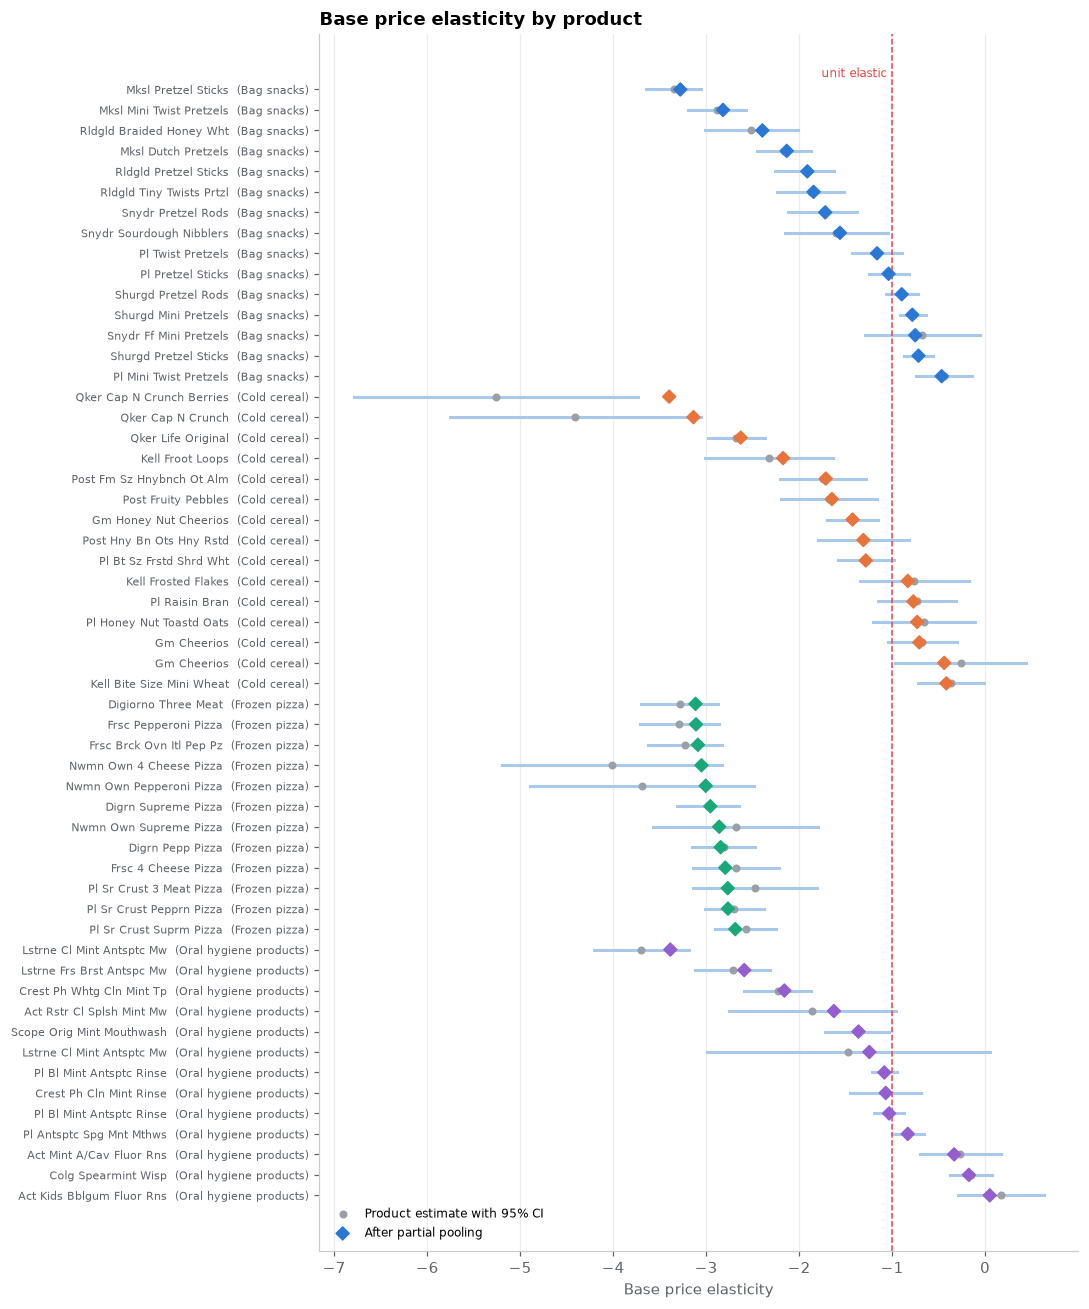

In [10]:
plot = est.sort_values(["category", "elasticity_base_pooled"])
fig, ax = plt.subplots(figsize=(10, 12))
y = np.arange(len(plot))[::-1]
for (yy, r) in zip(y, plot.itertuples()):
    ax.plot([r.elasticity_base - 1.96 * r.se_base, r.elasticity_base + 1.96 * r.se_base], [yy, yy], color=LIGHT_BLUE, lw=2)
ax.scatter(plot.elasticity_base, y, color=GRAY, s=18, zorder=3, label="Product estimate with 95% CI")
ax.scatter(plot.elasticity_base_pooled, y, color=[CAT_COLORS[c] for c in plot.category], s=36, zorder=4,
           marker="D", label="After partial pooling")
ax.set_yticks(y, [f"{r.description.title()}  ({r.category})" for r in plot.itertuples()], fontsize=7.5)
ax.axvline(-1, color=RED, ls="--", lw=1)
ax.text(-1.05, y.max() + 0.6, "unit elastic", color=RED, fontsize=8, ha="right")
ax.set(xlabel="Base price elasticity", title="Base price elasticity by product")
ax.legend(loc="lower left", fontsize=8)
ax.grid(axis="y", visible=False)
save(fig, "pricing_04_elasticity_forest")

**Findings.**

- **Every category is elastic on average** (below -1): a 1% price increase loses more than 1% of units. Frozen pizza is by far the most sensitive, around -3, and with little spread between products: shoppers see pizzas as substitutes and switch brands for a dollar.
- **Private label is among the least sensitive** in pretzels and cereal (about -0.5 to -1.3). Shoppers who buy the store brand are already buying on price and have nowhere cheaper to go.
- **Big national brands vary.** Cheerios and Mini Wheats are inelastic (about -0.4); Cap'n Crunch and Mike-sell's pretzels are very elastic (beyond -2).
- **Partial pooling matters for a few products.** Cap'n Crunch Berries moves from about -5.3 to about -3.4: its own estimate is extreme and imprecise, so the category average deserves weight.

## 7. Promotion effects

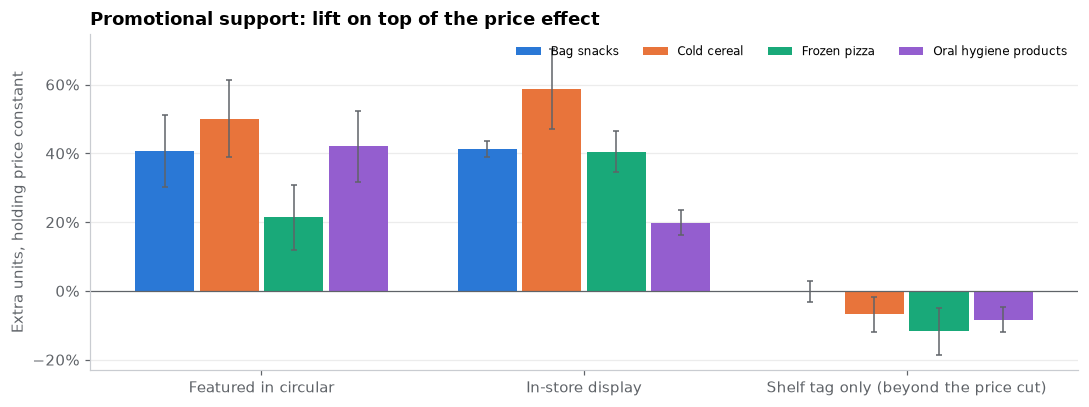

label,Featured in circular,In-store display,Shelf tag only (beyond the price cut)
category,,,
Bag snacks,+41%,+41%,-0%
Cold cereal,+50%,+59%,-7%
Frozen pizza,+21%,+41%,-12%
Oral hygiene products,+42%,+20%,-8%


In [11]:
pe = promos.assign(label=promos.term.map(pr.PROMO_LABELS))
fig, ax = plt.subplots(figsize=(10, 3.8))
cats = list(CAT_COLORS)
terms = ["is_feature", "is_display", "is_tpr_only"]
w = 0.2
for i, c in enumerate(cats):
    g = pe[pe.category == c].set_index("term").loc[terms]
    x = np.arange(len(terms)) + (i - 1.5) * w
    ax.bar(x, g.lift, width=w * 0.92, color=CAT_COLORS[c], label=c)
    ax.errorbar(x, g.lift, yerr=1.96 * g.se * np.exp(g.estimate), fmt="none", ecolor=MUTED, lw=1, capsize=2)
ax.set_xticks(np.arange(len(terms)), [pr.PROMO_LABELS[t] for t in terms])
ax.axhline(0, color=MUTED, lw=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(ylabel="Extra units, holding price constant", title="Promotional support: lift on top of the price effect")
ax.legend(fontsize=8, ncol=4, loc="upper right")
ax.grid(axis="x", visible=False)
save(fig, "pricing_05_promotion_lift")
pe.pivot(index="category", columns="label", values="lift").style.format("{:+.0%}")

- **A circular feature and an in-store display each add roughly 20 to 60% more units** on top of whatever the discount does. Display works best in cereal, the circular in cereal, pretzels and mouthwash.
- **A shelf tag alone adds nothing beyond the price cut** (the coefficient is around zero or slightly negative). The lift of a tag-only promotion is the discount itself; the tag does not attract shoppers on its own.

### Is there a price threshold?

Constant elasticity assumes every percentage point of discount works the same. The next regression replaces the discount with depth bands, keeping all controls.

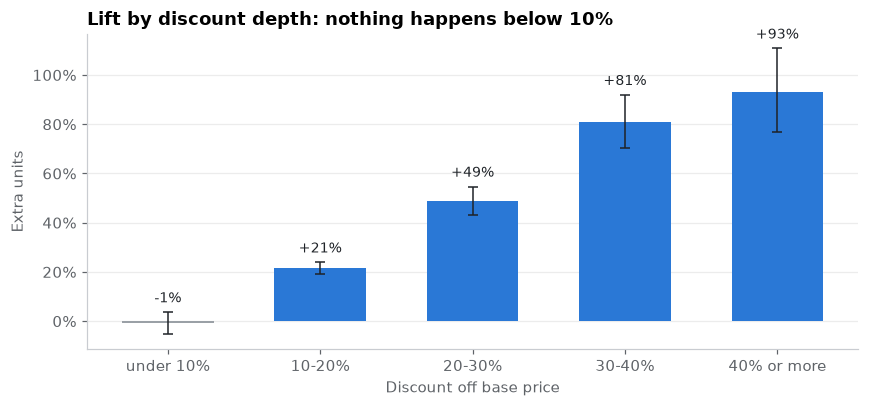

In [12]:
d["depth_band"] = pd.cut(d.discount_depth, [-0.01, 0.005, 0.10, 0.20, 0.30, 0.40, 1.0],
                         labels=["none", "under 10%", "10-20%", "20-30%", "30-40%", "40% or more"])
t = pr._feols("log_units ~ i(depth_band, ref='none') + is_feature + is_display | store_product + category_week", d).tidy()
bands = t[t.index.str.startswith("depth_band")].copy()
bands.index = bands.index.str.replace("depth_band::", "")
bands["lift"] = np.exp(bands.Estimate) - 1
bands["low"], bands["high"] = np.exp(bands["2.5%"]) - 1, np.exp(bands["97.5%"]) - 1
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(bands))
ax.bar(x, bands.lift, color=[GRAY] + [BLUE] * (len(bands) - 1), width=0.6)
ax.errorbar(x, bands.lift, yerr=[bands.lift - bands.low, bands.high - bands.lift], fmt="none", ecolor=INK, lw=1, capsize=3)
for i, v in enumerate(bands.lift):
    ax.text(i, max(v, bands.high.iloc[i]) + 0.04, f"{v:+.0%}", ha="center", fontsize=9, color=INK)
ax.set_xticks(x, bands.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(xlabel="Discount off base price", ylabel="Extra units", title="Lift by discount depth: nothing happens below 10%")
ax.grid(axis="x", visible=False)
save(fig, "pricing_06_discount_depth")

**A clear threshold.** Discounts under 10% produce no measurable lift: shoppers do not notice them, so they only give margin away. From 10% the response is strong and roughly linear up to 40%, after which it flattens. In practice: **never run a promotion below 10% off**, and treat 40% as a ceiling where each extra point buys very little.

## 8. Side effects of promotions

Two classic objections to promotions can be tested with the same model:

- **Pantry loading.** If shoppers stock up during a promotion, sales should dip the week after. Test: add an indicator for "promoted last week" (and "promoted next week", a placebo that should be zero).
- **Cannibalization.** A promotion may steal units from other products in the same category. Test: add the share of the *other* products in the category that are on promotion in the same store and week.

In [13]:
d = d.sort_values(["upc", "store_id", "week_end"])
d["promo_last_week"] = d.groupby(["upc", "store_id"]).is_promo.shift(1).fillna(0)
d["promo_next_week"] = d.groupby(["upc", "store_id"]).is_promo.shift(-1).fillna(0)
grp = d.groupby(["store_id", "category", "week_end"])
n, k = grp.upc.transform("size"), grp.is_promo.transform("sum")
d["rival_promo_share"] = ((k - d.is_promo) / (n - 1)).fillna(0)
rows = []
for c, g in d.groupby("category"):
    t = pr._feols("log_units ~ i(upc, log_base_price) + i(upc, log_price_ratio) + is_feature + is_display + is_tpr_only"
                  " + promo_last_week + promo_next_week + rival_promo_share | store_product + category_week", g).tidy()
    for term in ["promo_last_week", "promo_next_week", "rival_promo_share"]:
        rows.append({"category": c, "term": term, "effect": np.exp(t.loc[term, "Estimate"]) - 1,
                     "low": np.exp(t.loc[term, "2.5%"]) - 1, "high": np.exp(t.loc[term, "97.5%"]) - 1})
side = pd.DataFrame(rows)
labels = {"promo_last_week": "Week after own promotion", "promo_next_week": "Week before own promotion (placebo)",
          "rival_promo_share": "All rivals in the category on promotion"}
side["term"] = side.term.map(labels)
side.pivot(index="category", columns="term", values="effect")[list(labels.values())].style.format("{:+.1%}")

term,Week after own promotion,Week before own promotion (placebo),All rivals in the category on promotion
category,,,
Bag snacks,+1.7%,+4.3%,-10.4%
Cold cereal,-0.1%,+2.9%,-19.5%
Frozen pizza,+3.6%,+6.8%,-5.3%
Oral hygiene products,-0.9%,+1.0%,-1.1%


- **No pantry loading.** The week after a promotion sells about the same as any other week (within a few percent, and slightly positive for pizza). Shoppers in this data are not stocking up enough to dent the following week, so promotional lift is mostly genuine extra volume for the product, not borrowed from next week. The placebo is slightly positive rather than exactly zero because promotions often run several weeks in a row, so 'promoted next week' partly flags weeks inside a promotion spell; neither term shows a dip.
- **Cannibalization is real in cereal and pretzels.** When all rival products in the category are on promotion, a product loses about 20% of its units in cereal and about 10% in pretzels. Part of any promotion's lift in those categories is volume moved from other products on the same shelf, which matters for the retailer, who owns the whole shelf. In pizza and mouthwash the effect is small or absent.

## 9. Out-of-time validation

Coefficients can look plausible and still describe the past badly. The test: fit on everything before the last 26 weeks, then predict units for every store-product-week in those 26 weeks.

Week effects for future weeks are unknown, so the predictive version replaces *category x week* with *category x week of year* plus *category x year*. Predictions are converted back from logs with Duan's smearing factor (the mean of the exponentiated residuals), which corrects the downward bias of exponentiating a log forecast.

In [14]:
val = pr.validate(d)
v = pd.DataFrame({k: {m: s["wape"] for m, s in val[k].items()} for k in ["all_weeks", "promoted_weeks"]})
v.columns = ["WAPE, all weeks", "WAPE, promoted weeks"]
v["bias, all weeks"] = [val["all_weeks"][m]["bias"] for m in v.index]
display(v.style.format({"WAPE, all weeks": "{:.1%}", "WAPE, promoted weeks": "{:.1%}", "bias, all weeks": "{:+.1%}"}))
display(Markdown(
    f"Holdout from **{val['holdout_start']}**: {val['rows']:,} store-product-weeks "
    f"({val['rows_without_history']:,} rows for store-products never seen in training are excluded)."))

,"WAPE, all weeks","WAPE, promoted weeks","bias, all weeks"
"Store-product average, last 13 weeks",46.6%,49.5%,+4.6%
Seasonality only,48.2%,50.3%,+10.3%
Seasonality + price and promotions,34.9%,38.6%,-0.8%


Holdout from **2011-07-13**: 82,947 store-product-weeks (3,531 rows for store-products never seen in training are excluded).

Knowing the price and the promotion plan cuts the forecast error by about a quarter compared with the store-product's own recent average, and the bias almost disappears. On promoted weeks the baselines under-forecast by about 30%, because they cannot know a promotion is coming; the model is within a few percent. The elasticities are not just descriptive: they **predict**.

## 10. Promotion economics

Volume is not the goal; profit is. The dataset has prices but no costs, so a **gross margin of 30% at the regular price** is assumed, typical for these grocery categories. Under that assumption, each product's typical promotion (its own average discount) is evaluated in three versions.

In [15]:
baselines = pr.product_baselines(d).merge(est.drop(columns=["category", "description", "manufacturer"]), on="upc")
effects = {c: {t: v for t, v in g.set_index("term").estimate.items()} for c, g in promos.groupby("category")}
rows = []
for r in baselines.itertuples():
    depth = r.avg_discount_when_promoted if pd.notna(r.avg_discount_when_promoted) else 0.2
    for mech, kw in {"Shelf tag only": {}, "With display": {"display": True},
                     "With circular and display": {"feature": True, "display": True}}.items():
        s = pr.simulate(pd.Series(r._asdict()), effects, discount=depth, **kw)
        rows.append({"category": r.category, "product": r.description, "mechanic": mech, "discount": depth,
                     "units_change": s["units_change"], "revenue_change": s["revenue_change"],
                     "profit_change": s["gross_profit_change"]})
promo_econ = pd.DataFrame(rows)
summary = promo_econ.groupby(["category", "mechanic"])[["discount", "units_change", "revenue_change", "profit_change"]].median().unstack()
summary["profit_change"].style.format("{:+.0%}")

mechanic,Shelf tag only,With circular and display,With display
category,,,
Bag snacks,-37%,+26%,-10%
Cold cereal,-58%,+7%,-29%
Frozen pizza,-55%,-12%,-28%
Oral hygiene products,-42%,+8%,-24%


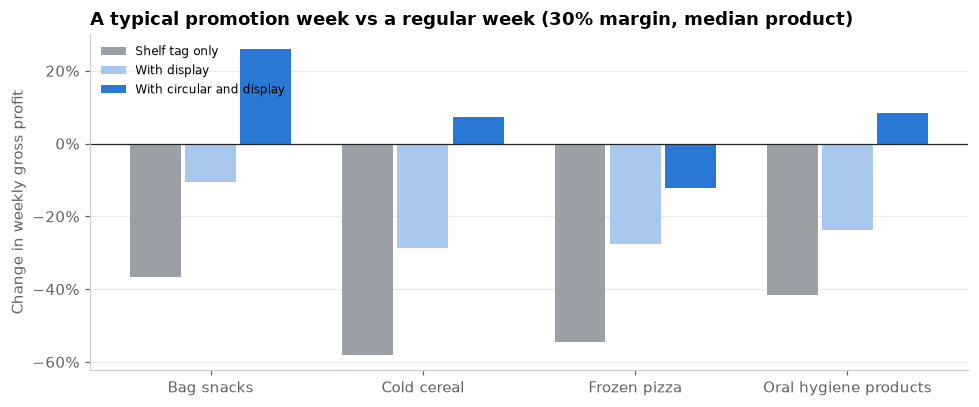

In [16]:
pivot = promo_econ.pivot_table(index="category", columns="mechanic", values="profit_change", aggfunc="median")
pivot = pivot[["Shelf tag only", "With display", "With circular and display"]]
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(pivot))
for i, (m, color) in enumerate(zip(pivot.columns, [GRAY, LIGHT_BLUE, BLUE])):
    ax.bar(x + (i - 1) * 0.26, pivot[m], width=0.24, color=color, label=m)
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(x, pivot.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(ylabel="Change in weekly gross profit", title="A typical promotion week vs a regular week (30% margin, median product)")
ax.legend(fontsize=8, loc="upper left")
ax.grid(axis="x", visible=False)
save(fig, "pricing_07_promotion_profit")

**At a 30% margin, a typical shelf-tag-only promotion loses 35 to 60% of a regular week's gross profit.** A display roughly halves the loss; only with a circular *and* a display does the typical promotion break even or make money in pretzels, cereal and mouthwash. Frozen pizza still loses, because its usual discounts leave almost no margin even after a strong volume response. That is the economic logic behind supplier-funded promotions: the extra volume from support has to pay for the discount. Two caveats push the real answer further down: suppliers' funding is not in the data (it would improve the picture), while cannibalization (section 8) means part of the extra volume in cereal and pretzels comes from other products on the same shelf (it worsens it).

## 11. Base price recommendations

For a small price increase, profit rises when the elasticity is smaller in magnitude than **1 / margin**. At a 30% margin that break-even point is about -3.3: any product less elastic than that would earn more at a higher price. Under constant elasticity, the profit-maximizing price follows the **Lerner rule**, price = cost x e / (1 + e). Because extrapolating a constant elasticity far from observed prices is risky, recommendations are capped at plus or minus 10%, well inside the price variation the data covers.

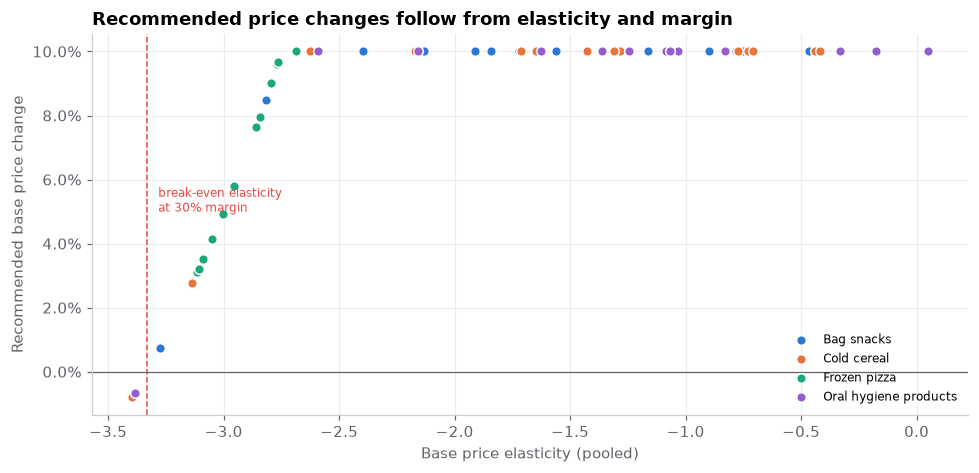

,20% margin,30% margin,40% margin,50% margin
test an increase,100%,95%,65%,58%
hold,0%,5%,0%,0%
test a decrease,0%,0%,35%,42%


In [17]:
margin = DEFAULT_GROSS_MARGIN
recs = baselines.apply(lambda r: pr.recommend(r, margin), axis=1, result_type="expand")
baselines["recommended_change"], baselines["recommendation"] = recs[0], recs[1]
fig, ax = plt.subplots(figsize=(9, 4.4))
for c, g in baselines.groupby("category"):
    ax.scatter(g.elasticity_base_pooled, g.recommended_change, color=CAT_COLORS[c], s=40, label=c, edgecolor="white")
ax.axvline(-1 / margin, color=RED, ls="--", lw=1)
ax.text(-1 / margin + 0.05, 0.05, f"break-even elasticity\nat {margin:.0%} margin", color=RED, fontsize=8)
ax.axhline(0, color=MUTED, lw=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(xlabel="Base price elasticity (pooled)", ylabel="Recommended base price change",
       title="Recommended price changes follow from elasticity and margin")
ax.legend(fontsize=8, loc="lower right")
save(fig, "pricing_08_recommendations")
sens = pd.DataFrame({f"{m:.0%} margin": baselines.apply(lambda r: pr.recommend(r, m)[0], axis=1).pipe(
    lambda s: pd.Series({"test an increase": (s > 0.02).mean(), "hold": s.abs().le(0.02).mean(), "test a decrease": (s < -0.02).mean()}))
    for m in (0.2, 0.3, 0.4, 0.5)})
sens.style.format("{:.0%}")

At a 30% margin almost every product is less elastic than the break-even point, so the arithmetic says "test a higher price" for nearly all of them. The sensitivity table shows how strongly that depends on the margin: from 40% upwards, frozen pizza and the most elastic brands flip to "test a decrease", because each lost unit now costs more profit.

Why the model does not simply say "raise everything":

- **These are product elasticities.** A shopper who leaves a product because of a price rise often buys another product on the same shelf (section 8). For the retailer, the category elasticity is lower than the product's, which makes increases look even better, but the retailer also has a price image to protect.
- **Competitors are not in the data.** A rival chain's prices and responses would change the answer.
- **Recommendations are tests, not decisions.** The right next step is a controlled price test: raise the price in a random half of comparable stores for a few weeks and measure the difference, the same design the model approximates statistically.

## 12. The simulator

The same functions power the app's simulator page and the AI analyst's pricing tool. Two examples:

In [18]:
def scenario(desc, **kw):
    row = baselines[baselines.description == desc].iloc[0]
    s = pr.simulate(row, effects, **kw)
    return {"product": desc.title(), "scenario": ", ".join(f"{k}={v}" for k, v in kw.items()),
            "units": s["units"], "units vs regular week": s["units_change"],
            "revenue vs regular week": s["revenue_change"], "gross profit vs regular week": s["gross_profit_change"]}

examples = pd.DataFrame([
    scenario("DIGRN PEPP PIZZA", discount=0.15, feature=True, display=True),
    scenario("DIGRN PEPP PIZZA", discount=0.25, feature=True, display=True),
    scenario("GM HONEY NUT CHEERIOS", base_price_change=0.05),
    scenario("GM HONEY NUT CHEERIOS", discount=0.08),
])
examples.style.format({"units": "{:,.0f}", "units vs regular week": "{:+.0%}", "revenue vs regular week": "{:+.0%}",
                       "gross profit vs regular week": "{:+.0%}"}).hide(axis="index")

product,scenario,units,units vs regular week,revenue vs regular week,gross profit vs regular week
Digrn Pepp Pizza,"discount=0.15, feature=True, display=True","3,320",+194%,+150%,+47%
Digrn Pepp Pizza,"discount=0.25, feature=True, display=True","5,053",+348%,+236%,-25%
Gm Honey Nut Cheerios,base_price_change=0.05,"3,678",-7%,-2%,+9%
Gm Honey Nut Cheerios,discount=0.08,"3,942",+0%,-8%,-27%


Two lessons in four rows. **Depth matters as much as support:** with the same circular and display, a 15% pizza discount is a profitable week, while 25% loses money despite selling far more units. **Small discounts are pure cost:** an 8% Cheerios discount sits below the 10% threshold, so the simulator gives it no volume response and it only gives margin away, while a 5% base price increase on the same product raises profit.

## 13. Conclusions

1. **Fixed effects change the answer.** A naive regression says elasticity is about -1; controlling for store and product differences, the week, and promotional support gives about -1.7 on average, with large differences by product. Getting the specification right matters more than the choice of algorithm.
2. **Frozen pizza is the price-sensitive category** (about -3); private label and big cereal brands like Cheerios are the least sensitive.
3. **Support drives promotions.** A circular or a display adds 20 to 60% on top of the discount; a shelf tag alone adds nothing. Discounts under 10% do not move volume at all.
4. **No pantry loading, but real cannibalization** in cereal and pretzels: part of a promotion's lift there is taken from other products on the same shelf.
5. **The model predicts unseen weeks** about 25% better than a store-product's recent average, and removes the 30% under-forecast that baselines have in promoted weeks.
6. **At a 30% margin, unsupported promotions lose money and only moderate, well-supported discounts pay**, while most base prices look low. Both conclusions depend on the margin, which the simulator lets the user change, and should be confirmed with controlled tests.

## 14. Limitations and next steps

| Area | Limitation | Next step |
|---|---|---|
| Costs | No cost or supplier funding data; margin is assumed | Load real unit costs and trade funds per promotion, then optimise the promotion calendar on actual profit |
| Cross-effects | Cannibalization is measured as an average, not product by product | Estimate a cross-price matrix within each category (or a discrete choice model) and simulate category profit |
| Causality | Prices and promotions are observational; fixed effects remove most, not all, confounding | Run randomized store-level price tests; use the model to choose which products to test first |
| Dynamics | Constant elasticity and a one-week window | Allow elasticity to vary with price level and season; model reference-price effects of frequent promotions |
| Stores | One elasticity per product across all stores | Interact elasticity with store price tier (upscale, mainstream, value) for zone pricing |
| Competition | No competitor prices | Add competitor price indices where available |